# Saccade video

In [ ]:
BASE_FOLDER = '/home/asyeda/stringerlab_dm11/eye-vs-face/' # set path parent folder called eye-vs-facce which should contain 'data' folder

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys
sys.path.append(os.path.join(BASE_FOLDER, 'analysis/code'))
import nonlinear_modelv3
import helper_functions
from glob import glob
import cv2
from matplotlib.animation import FuncAnimation
from matplotlib import animation
from scipy.stats import zscore
from matplotlib.widgets import Slider
import pupil_dark_helpers as pdh
from scipy.io import loadmat

## Helper functions

In [2]:
def load_video_frames(video_path):
    # Load the video
    cap = cv2.VideoCapture(video_path)

    # Get the properties of the video
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    # Read the first frame as the reference
    frames = []

    # Read the rest of the frames
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        # convert the frame to grayscale
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frames.append(frame)

    # Convert the frames to a numpy array
    frames = np.array(frames)

    # Close the video
    cap.release()

    return frames, fps

def update_brightness(image, brightness_factor):
    """
    Update the brightness of the image
    """
    brightness_factor = float(brightness_factor)/100
    # Ensure that the brightness factor is within a valid range
    brightness_factor = max(0.0, min(brightness_factor, 2.0))
    # Adjust the brightness by multiplying with the factor
    brightened_image_array = image * brightness_factor
    # Make sure the values are still in the valid 0-1 range
    brightened_image_array = np.clip(brightened_image_array, 0.0, 1.0)
    return brightened_image_array


def remove_spines(ax):
    for loc, spine in ax.spines.items():
        spine.set_linewidth(0)


### Load data

In [ ]:
dbs = pdh.get_light_static_info()
mouse_list = np.unique([entry['mname'] for entry in dbs])
mouse_list

Sessions from get_light_static_info >>>


array(['LZ16', 'TX139', 'TX140', 'TX143', 'TX150'], dtype='<U5')

In [ ]:
mname = 'TX140' # CHECK LZ16, TX139, TX143: process again in random recording folder and save npz_data
datexp = [entry['datexp'] for entry in dbs if entry['mname'] == mname][0]
spks, xpos, ypos, tcams, tneurals, _, _, npz_data = nonlinear_modelv3.load_data(f"{BASE_FOLDER}data/mouse_data/{mname}/{datexp}", mname, datexp)

In [ ]:
# Load eye video
small_videos_path_list = sorted(glob(f"{BASE_FOLDER}data/mouse_data/{mname}/{datexp}/{mname}_{datexp}_*small.mp4"))
print(small_videos_path_list)
small_frames = []
for small_video_path in small_videos_path_list:
    small_frames_, fps = helper_functions.load_video_frames(small_video_path)
    small_frames.append(small_frames_)
small_frames = np.concatenate(small_frames)
print(small_frames.shape)

['/home/asyeda/pupil_analysis/light_recordings_static/TX140_2024_11_06_1_small.mp4']
(360526, 41, 61)


In [ ]:
# Load face video
full_videos_path_list = sorted(glob(f"{BASE_FOLDER}data/mouse_data/{mname}/{datexp}/{mname}_{datexp}_*full.mp4"))
print(full_videos_path_list)
full_frames = []
for video_path in full_videos_path_list:
    full_frames_, fps = helper_functions.load_video_frames(video_path)
    full_frames.append(full_frames_)
full_frames = np.concatenate(full_frames)
print(full_frames.shape)

['/home/asyeda/pupil_analysis/light_recordings_static/TX140_2024_11_06_1_full.mp4']
(360526, 200, 272)


In [ ]:
# Load pupil position data
proc_data = np.load(f"{BASE_FOLDER}data/mouse_data/{mname}/{datexp}/{mname}_{datexp}_1_small_proc.npy", allow_pickle=True).item()
pupil_roi = [x for x in proc_data['rois'] if x['rtype'] == 'Pupil']
x_offset = pupil_roi[0]['xrange'][0]
y_offset = pupil_roi[0]['yrange'][0]
# Load pupil data from npz file
pupil_x = npz_data['pupil_x_small']
pupil_y = npz_data['pupil_y_small']
blink = npz_data['blink_small']   
running_speed = npz_data['running_speed']
running_time = npz_data['running_time']
# Interpolate running speed to match pupil timestamps
running_speed = helper_functions.interp_value(npz_data['running_speed'].copy(), running_time, npz_data['tcam'].item()['blk1'])

In [ ]:
saccade_labels_filename = f"{BASE_FOLDER}data/mouse_data/{mname}/{datexp}/finetuned_labels/curated_posthoc/{mname}_{datexp}_finetuned_model_labels.mat"
saccade_labels = loadmat(saccade_labels_filename)['eye_movement_data']['Saccade'][0,0].squeeze()
sac_start_idx = np.where(np.diff(saccade_labels) == 1)[0] + 1
sac_end_idx = np.where(np.diff(saccade_labels) == -1)[0] + 1

In [9]:
from facemap.pose import refine_pose

# load keypoints data
whisker_color = "#c92814ff"
nose_color = "#6bfbbaff"

pupil_x = npz_data['pupil_x_small']
pupil_y = npz_data['pupil_y_small']
pose_x_coord = npz_data['pose_x_coord']
pose_y_coord = npz_data['pose_y_coord']
bodyparts = refine_pose.BODYPARTS

whisker_indices = [bodyparts.index(part) for part in bodyparts if 'whisker' in part]
whisker_x_centroid = np.nanmean(pose_x_coord[whisker_indices, :], axis=0)
whisker_x_centroid = whisker_x_centroid - whisker_x_centroid.mean()
whisker_y_centroid = np.nanmean(pose_y_coord[whisker_indices, :], axis=0) 
whisker_y_centroid = whisker_y_centroid - whisker_y_centroid.mean()

nose_indices = [bodyparts.index(part) for part in bodyparts if 'nose' in part and 'bridge' not in part]
nose_x_centroid = np.nanmean(pose_x_coord[nose_indices, :], axis=0)
nose_x_centroid = nose_x_centroid - nose_x_centroid.mean() 
nose_y_centroid = np.nanmean(pose_y_coord[nose_indices, :], axis=0)
nose_y_centroid = nose_y_centroid.T - nose_y_centroid.mean() 

## Save video

/tmp/ipykernel_970673/2724513784.py:83: UserWarning: You passed a edgecolor/edgecolors ('w') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  pupil_scat = ax1.scatter([], [], c='yellow', s=300, edgecolors='w', linewidths=2, marker='x')


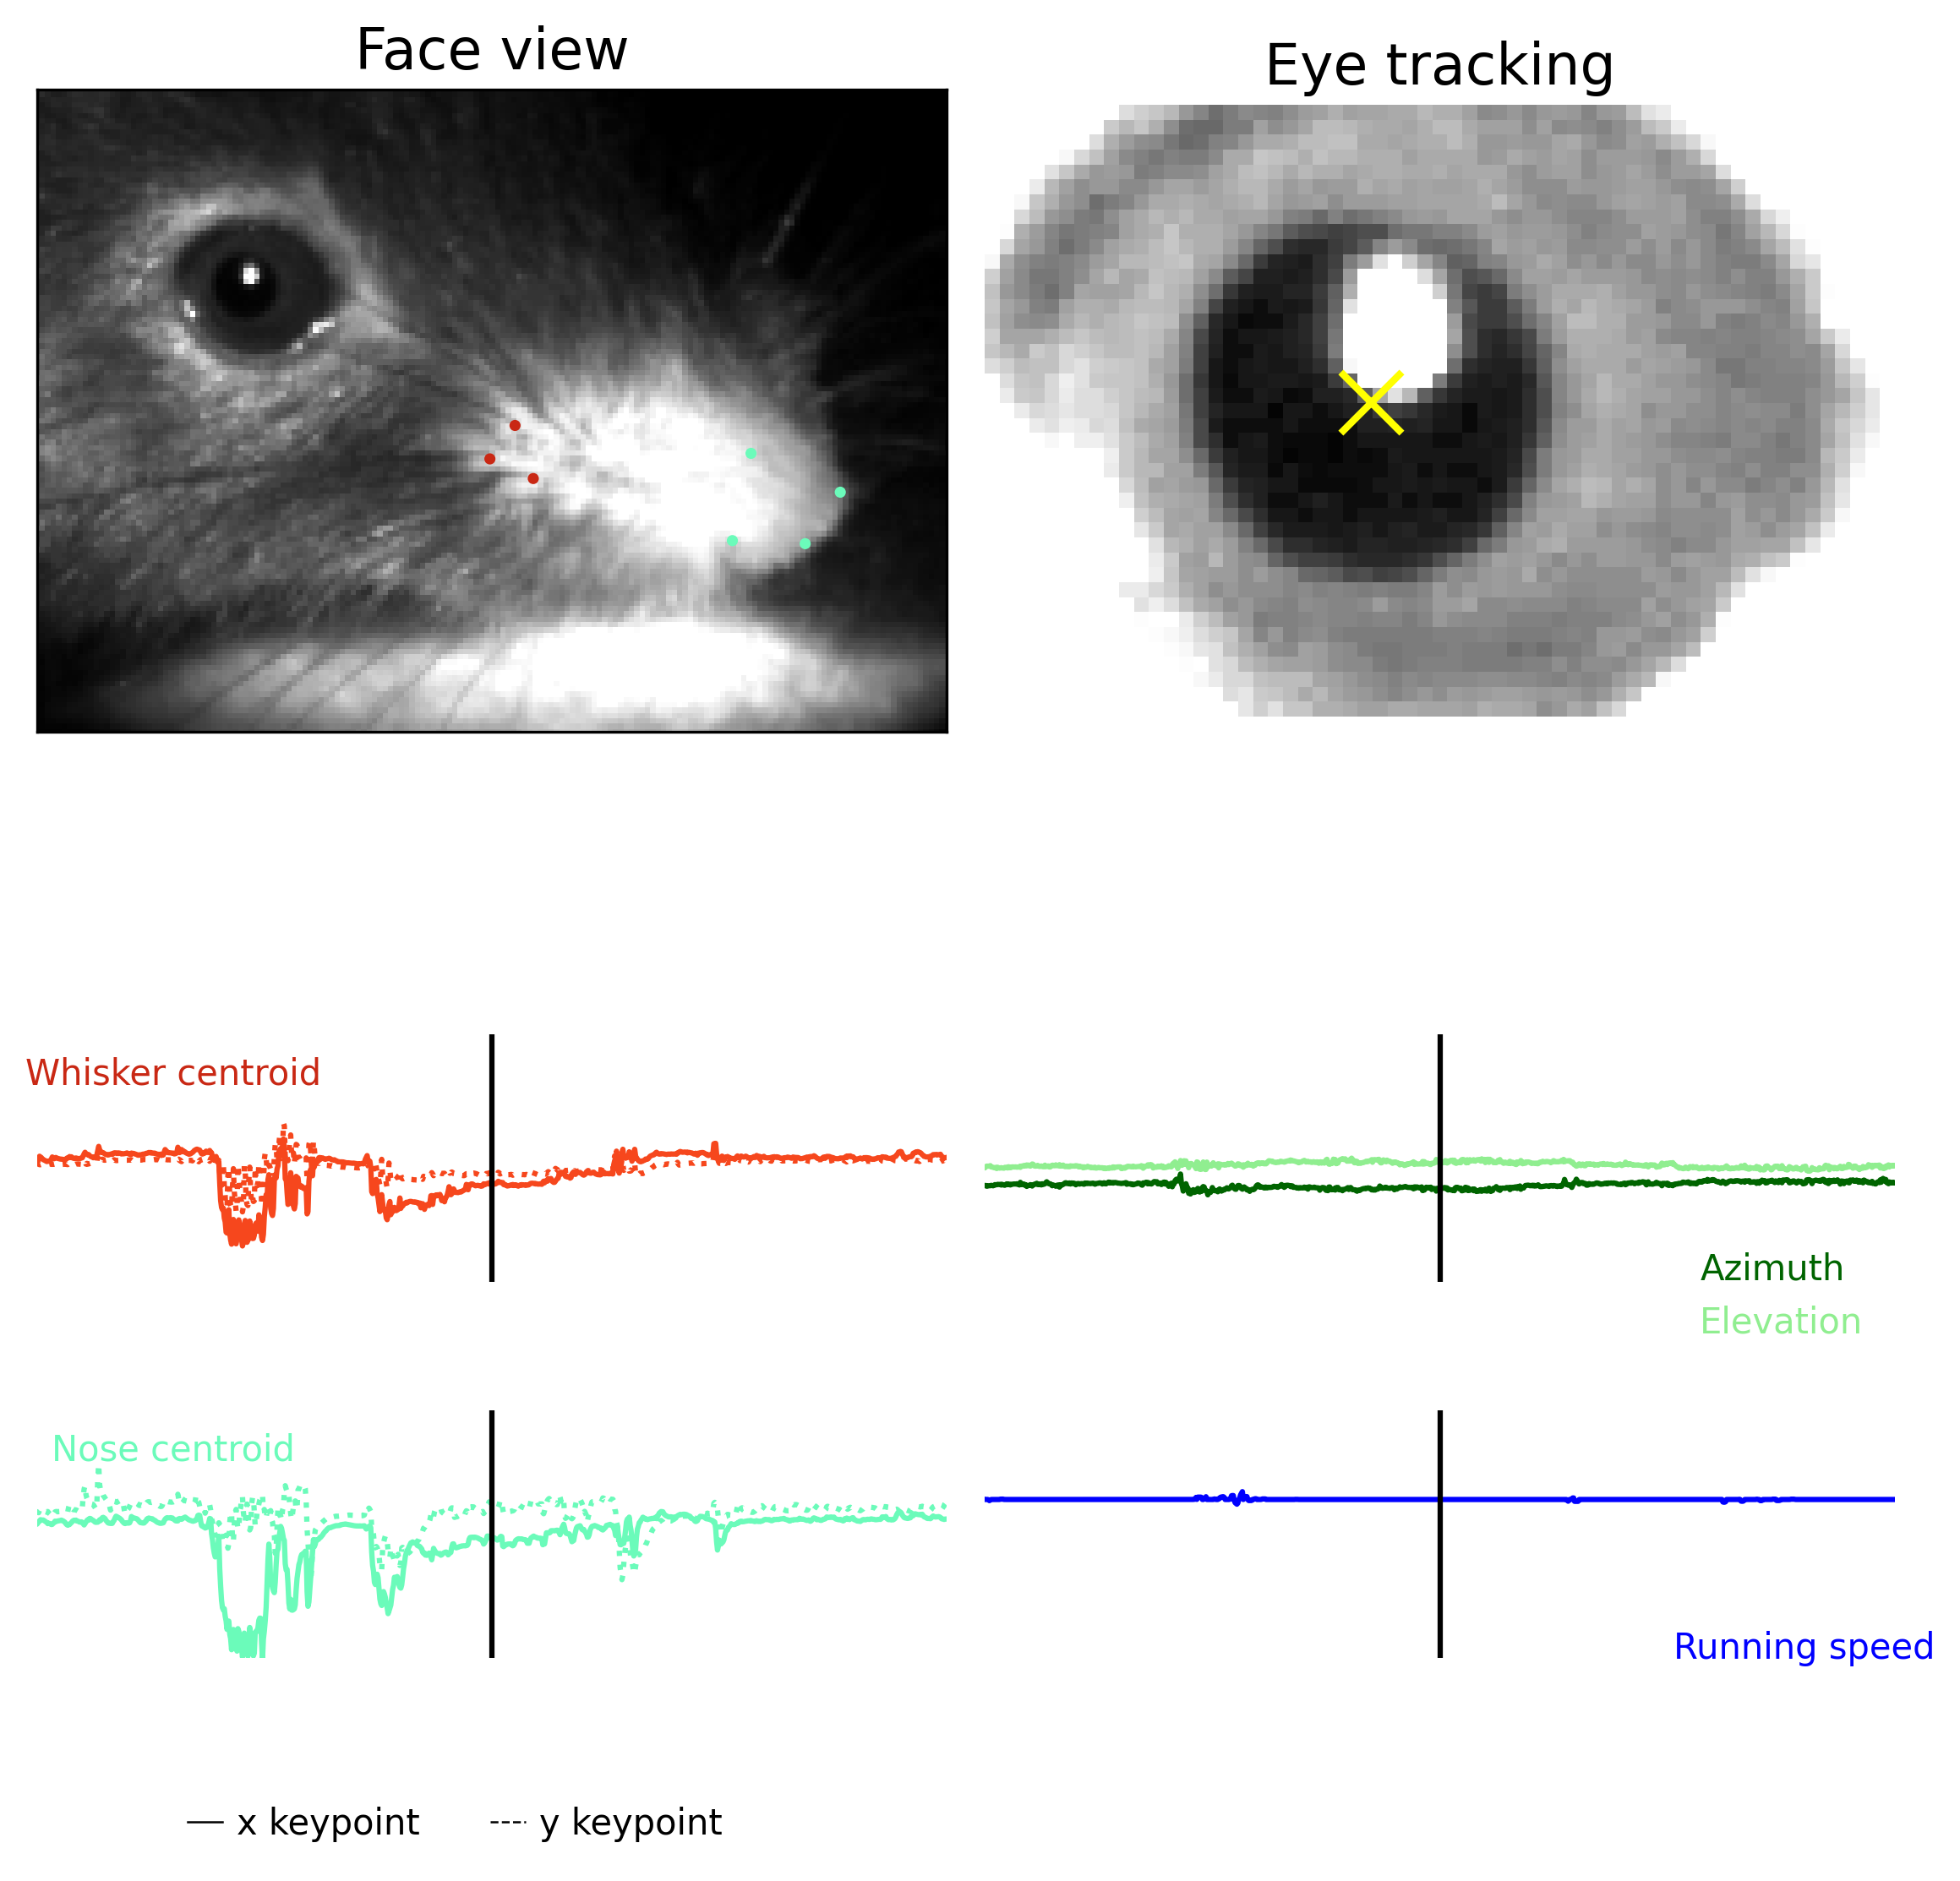

In [12]:
%matplotlib inline
from matplotlib.widgets import Slider, TextBox
from matplotlib import gridspec

# Helper to create multiple scatter plots
def create_scatters(ax, indices, color):
    scatters = []
    for _ in indices:
        sc = ax.scatter([], [], c=color, s=10, edgecolors='none', linewidths=2, marker='o')
        scatters.append(sc)
    return scatters


neural_xmin = 0
neural_xmax = 1000 #X_embedding.shape[1]-1
pupil_xmin = 98800 #np.argmin(np.abs(pupil_timestamp - spks_timestamp[neural_xmin]))
pupil_xmax = 102500 #np.argmin(np.abs(pupil_timestamp - spks_timestamp[neural_xmax]))
pupil_xy = np.vstack((pupil_x, pupil_y)).T

# Create a 3x2 grid with height ratios for the rows
fig = plt.figure(figsize=(8, 8), dpi=300)
gs = gridspec.GridSpec(3, 2, height_ratios=[1, .25, .25])
plt.subplots_adjust(left=0.1, bottom=0.3)  # Leave space for the slider and text box


# Span the image across both rows in the first column (ax1)
ax3 = plt.subplot(gs[0,0]) # face view
ax5 = plt.subplot(gs[1,0]) # whisker pose trace
ax4 = plt.subplot(gs[2,0]) # nose pose trace
ax1 = plt.subplot(gs[0,1]) # eye tracking image
ax2 = plt.subplot(gs[1,1]) # pupil trace
ax2b = plt.subplot(gs[2,1]) # running speed trace
# shift position of running speed plot lower
pos = ax2b.get_position()
pos.y0 = pos.y0 - 0.1
ax2b.set_position(pos)

# Rest of the code...
tlag = 200  # Time lag for the traces 

# Initial plot setup for the full frame (ax3)
full_frame_with_adjusted_contrast = update_brightness(full_frames[0], 0.1)
img_full = ax3.imshow(full_frame_with_adjusted_contrast, cmap='gray')


# Nose and whisker scatter plots
nose_scat = create_scatters(ax3, nose_indices, nose_color)
whisker_scat = create_scatters(ax3, whisker_indices, whisker_color)

ax3.set_title('Face view', fontsize=16)
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_ylim(120, 0)
ax3.set_xlim(70, 240)

# Plot x, y traces for pose keypoints (ax4)
ax4.plot(nose_x_centroid, color="#6bfbbaff", label='Nose X')
ax4.plot(nose_y_centroid, color="#6bfbbaff", linestyle=':', label='Nose Y')
ax4.set_ylim(-10, 10)
nose_vline = ax4.axvline(0, color='k', linestyle='-')
remove_spines(ax4)
ax4.set_xticks([])
ax4.set_yticks([])
ax5.plot(whisker_x_centroid, color='#f6471dff', label='Whiskers X')
ax5.plot(whisker_y_centroid, color="#f6471dff", linestyle=':', label='Whiskers Y')
ax5.set_ylim(-10, 10)
remove_spines(ax5)
ax5.set_xticks([])
ax5.set_yticks([])
whisker_vline = ax5.axvline(0, color='k', linestyle='-')

ax4.text(0.15, 0.8, 'Nose centroid', transform=ax4.transAxes, ha='center', fontsize=10, color=nose_color)
ax5.text(0.15, 0.8, 'Whisker centroid', transform=ax5.transAxes, ha='center', fontsize=10, color=whisker_color)
h0,=ax4.plot(-100, 0,'k-', lw=.6)
h1,=ax4.plot(-100, 0,'k--', lw=.6)
ax4.legend([h0, h1], ['x keypoint', 'y keypoint'], loc=[.15, -.8], frameon=False,
            fontsize=10, ncols=2, handlelength=1, handletextpad=.4)


# Initial plot setup for the image (ax1)
frame_with_adjusted_contrast = update_brightness(small_frames[0], 1.8)
img = ax1.imshow(frame_with_adjusted_contrast, cmap='gray')
pupil_scat = ax1.scatter([], [], c='yellow', s=300, edgecolors='w', linewidths=2, marker='x')
ax1.set_title('Eye tracking', fontsize=16)
ax1.set_xticks([])
ax1.set_yticks([])

# Plot pupil x trace (ax2)
time = np.arange(pupil_xy.shape[0])
x_trace = ax2.plot(pupil_x, color='darkgreen', label='Azimuth')
ax2.plot(pupil_y, color='lightgreen', label='Elevation')
frame_vline_projection = ax2.axvline(0, color='k', linestyle='-')
# add saccade regions
for sac in zip(sac_start_idx, sac_end_idx):
    start, end = sac[0], sac[-1]
    ax2.vlines(start, np.min([pupil_xy]), np.max([pupil_xy]), color=(0,1,0), linestyle='--', lw=.8)
    #ax2.axvspan(start, end, color='green', alpha=0.3)
ax2.set_xlim(0, len(time) - 1)
ax2b.plot(running_speed, color='blue', label='Running speed')
ax2b.set_xlim(0, len(time) - 1)
ax2b.text(.9, 0, 'Running speed', transform=ax2b.transAxes, ha='center', 
          fontsize=10, color='blue')
running_vline = ax2b.axvline(0, color='k', linestyle='-')
ax2.set_xticks([])
ax2.set_yticks([])
ax2b.set_xticks([])
ax2b.set_yticks([])
remove_spines(ax1)
remove_spines(ax2)
remove_spines(ax2b)

legend = ax2.legend(facecolor='none', frameon=False, loc='upper right', bbox_to_anchor=(1, .25))
leg_colors = ['darkgreen', 'lightgreen']
for leg in legend.get_texts():
    leg.set_fontsize(10)
    leg.set_color(leg_colors.pop(0))
# remove legend lines 
for leg_line in legend.get_lines():
    leg_line.set_linewidth(0)

# Update function for the slider and text box
def update(frame_idx):
    frame_idx = int(frame_idx)  # Ensure the index is an integer
    tlag = 500  # Time lag for the traces
    # Update image
    frame_with_adjusted_contrast = update_brightness(small_frames[frame_idx], 1.8)
    img.set_data(frame_with_adjusted_contrast)
    # Update full frame image
    full_frame_with_adjusted_contrast = update_brightness(full_frames[frame_idx], 0.1)
    img_full.set_data(full_frame_with_adjusted_contrast)

    # Update scatter points
    pupil_scat.set_offsets([pupil_x[frame_idx]+x_offset, pupil_y[frame_idx]+y_offset])
    # Update nose scatters
    for sc, idx in zip(nose_scat, nose_indices):
        sc.set_offsets([pose_x_coord[idx, frame_idx], pose_y_coord[idx, frame_idx]])

    # Update whisker scatters
    for sc, idx in zip(whisker_scat, whisker_indices):
        sc.set_offsets([pose_x_coord[idx, frame_idx], pose_y_coord[idx, frame_idx]])

    # Update vertical lines in trace plots
    frame_vline_projection.set_xdata([frame_idx])
    nose_vline.set_xdata([frame_idx])
    whisker_vline.set_xdata([frame_idx])
    running_vline.set_xdata([frame_idx])

    # Adjust window around the current frame for zoom effect in traces
    ax2.set_xlim(max(0, frame_idx - tlag), min(len(time), frame_idx + tlag))
    ax2b.set_xlim(max(0, frame_idx - tlag), min(len(time), frame_idx + tlag))
    ax4.set_xlim(max(0, frame_idx - tlag), min(len(time), frame_idx + tlag))
    ax5.set_xlim(max(0, frame_idx - tlag), min(len(time), frame_idx + tlag))

# Create the animation object
ani = FuncAnimation(fig, update, frames=range(pupil_xmin, pupil_xmax, 10), interval=37, blit=False)

# Save the animation as a video
output_file = "supplement_video.mp4"

from matplotlib.animation import FFMpegWriter

writer = FFMpegWriter(
    fps=35,
    codec="mpeg4",
    extra_args=["-q:v", "5"]  # quality (lower = better, but bigger file)
)
ani.save("saccade.mp4", writer=writer, dpi=150)


plt.tight_layout()


plt.show()